# **1. Google Drive 연결**

In [1]:
# ============================================================
# 낚시성 기사 탐지 - 데이터 전처리 (Google Colab)
# ============================================================
# 사용법:
# 1. Google Drive에 AI Hub zip 파일들 업로드
# 2. 아래 DATA_PATH를 실제 경로로 수정
# 3. 셀 순서대로 실행
# ============================================================

from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# **2. 경로 설정**

In [2]:
# ⚠️ 아래 경로를 본인의 드라이브 경로로 수정하세요!

import os

# === 여기를 수정하세요! ===
# 예: '/content/drive/MyDrive/캡스톤/데이터/Training/2.라벨링데이터'
DATA_PATH = '/content/drive/MyDrive/2026 4-1 캡스톤/DATA/Training'

# 경로 확인
if os.path.exists(DATA_PATH):
    files = os.listdir(DATA_PATH)
    print(f"✅ 경로 확인 완료! 파일/폴더 {len(files)}개 발견")
    for f in files[:10]:
        print(f"  - {f}")
    if len(files) > 10:
        print(f"  ... 외 {len(files) - 10}개")
else:
    print("❌ 경로를 찾을 수 없습니다. DATA_PATH를 확인하세요!")

✅ 경로 확인 완료! 파일/폴더 43개 발견
  - Untitled0.ipynb
  - TL_Part1_Clickbait_Auto_EC.zip
  - TL_Part1_Clickbait_Auto_ET.zip
  - TL_Part1_Clickbait_Auto_GB.zip
  - TL_Part1_Clickbait_Auto_IS.zip
  - TL_Part1_Clickbait_Auto_LC.zip
  - TL_Part1_Clickbait_Auto_PO.zip
  - TL_Part1_Clickbait_Auto_SO.zip
  - TL_Part1_Clickbait_Direct_EC.zip
  - TL_Part1_Clickbait_Direct_ET.zip
  ... 외 33개


# **3. ZIP 파일 압축 해제**

In [3]:
import zipfile
import glob

# zip 파일 찾기
zip_files = glob.glob(os.path.join(DATA_PATH, '*.zip'))
print(f"📦 ZIP 파일 {len(zip_files)}개 발견")

# 압축 해제할 폴더
EXTRACT_PATH = '/content/clickbait_data'
os.makedirs(EXTRACT_PATH, exist_ok=True)

# 압축 해제
for i, zf in enumerate(zip_files):
    fname = os.path.basename(zf)
    print(f"[{i+1}/{len(zip_files)}] {fname} 압축 해제 중...")
    try:
        with zipfile.ZipFile(zf, 'r') as z:
            z.extractall(EXTRACT_PATH)
    except Exception as e:
        print(f"  ⚠️ 오류: {e}")

print(f"\n✅ 압축 해제 완료! 경로: {EXTRACT_PATH}")

📦 ZIP 파일 42개 발견
[1/42] TL_Part1_Clickbait_Auto_EC.zip 압축 해제 중...
[2/42] TL_Part1_Clickbait_Auto_ET.zip 압축 해제 중...
[3/42] TL_Part1_Clickbait_Auto_GB.zip 압축 해제 중...
[4/42] TL_Part1_Clickbait_Auto_IS.zip 압축 해제 중...
[5/42] TL_Part1_Clickbait_Auto_LC.zip 압축 해제 중...
[6/42] TL_Part1_Clickbait_Auto_PO.zip 압축 해제 중...
[7/42] TL_Part1_Clickbait_Auto_SO.zip 압축 해제 중...
[8/42] TL_Part1_Clickbait_Direct_EC.zip 압축 해제 중...
[9/42] TL_Part1_Clickbait_Direct_ET.zip 압축 해제 중...
[10/42] TL_Part1_Clickbait_Direct_GB.zip 압축 해제 중...
[11/42] TL_Part1_Clickbait_Direct_LC.zip 압축 해제 중...
[12/42] TL_Part1_Clickbait_Direct_IS.zip 압축 해제 중...
[13/42] TL_Part1_Clickbait_Direct_PO.zip 압축 해제 중...
[14/42] TL_Part1_Clickbait_Direct_SO.zip 압축 해제 중...
[15/42] TL_Part1_NonClickbait_Auto_EC.zip 압축 해제 중...
[16/42] TL_Part1_NonClickbait_Auto_ET.zip 압축 해제 중...
[17/42] TL_Part1_NonClickbait_Auto_GB.zip 압축 해제 중...
[18/42] TL_Part1_NonClickbait_Auto_IS.zip 압축 해제 중...
[19/42] TL_Part1_NonClickbait_Auto_LC.zip 압축 해제 중...
[20/42] TL_Par

In [4]:
# 압축 해제 결과 확인
import glob
json_files = glob.glob(os.path.join(EXTRACT_PATH, '**', '*.json'), recursive=True)
print(f"JSON 파일 {len(json_files):,}개 발견")

# 폴더 구조 확인
for item in os.listdir(EXTRACT_PATH)[:10]:
    print(f"  - {item}")

JSON 파일 586,741개 발견
  - SO_M06_903277_L.json
  - ET_M03_631357_L.json
  - PO_M03_662119_L.json
  - IS_M14_333262_L.json
  - EC_M05_712697_L.json
  - GB_M11_288389_L.json
  - ET_M13_267464_L.json
  - IS_M10_186952_L.json
  - EC_M04_618568_L.json
  - EC_M05_700084_L.json


# **4. JSON 파일 파싱 → DataFrame 변환**

In [5]:
import json
import pandas as pd
from tqdm import tqdm

# JSON 파일 전체 찾기
json_files = glob.glob(os.path.join(EXTRACT_PATH, '**', '*.json'), recursive=True)
print(f"📄 JSON 파일 {len(json_files):,}개 발견")


# JSON 파싱 함수
def parse_json(filepath):
    """JSON 파일 하나를 파싱하여 딕셔너리로 반환"""
    try:
        with open(filepath, 'r', encoding='utf-8') as f:
            data = json.load(f)

        source = data.get('sourceDataInfo', {})
        label = data.get('labeledDataInfo', {})

        # 기본 정보
        row = {
            'newsID': source.get('newsID', ''),
            'newsCategory': source.get('newsCategory', ''),
            'newsSubcategory': source.get('newsSubcategory', ''),
            'newsTitle': source.get('newsTitle', ''),
            'newsContent': source.get('newsContent', ''),
            'partNum': source.get('partNum', ''),           # P1 또는 P2
            'processType': source.get('processType', ''),   # A(자동) 또는 D(직접)
            'processLevel': source.get('processLevel', ''),
            'sentenceCount': source.get('sentenceCount', 0),
            'clickbaitClass': label.get('clickbaitClass', -1),  # 0=낚시성, 1=정상
        }

        # Part1: 낚시성 제목 + 참조 문장 비율 계산
        if source.get('partNum') == 'P1':
            row['fakeTitle'] = label.get('newTitle', '')
            refer_info = label.get('referSentenceInfo', [])
            if refer_info:
                y_count = sum(1 for s in refer_info if s.get('referSentenceyn') == 'Y')
                row['referSentenceRatio'] = y_count / len(refer_info)
            else:
                row['referSentenceRatio'] = 0.0
            row['subjectConsistencyRatio'] = None  # Part1에는 없음

        # Part2: 주제 일관성 비율 계산
        elif source.get('partNum') == 'P2':
            row['fakeTitle'] = ''
            process_info = label.get('processSentenceInfo', [])
            if process_info:
                y_count = sum(1 for s in process_info if s.get('subjectConsistencyYn') == 'Y')
                row['subjectConsistencyRatio'] = y_count / len(process_info)
            else:
                row['subjectConsistencyRatio'] = 0.0
            row['referSentenceRatio'] = None  # Part2에는 없음

        return row

    except Exception as e:
        return None


# 전체 JSON 파싱 (진행바 포함)
print("🔄 JSON 파싱 중... (시간이 좀 걸릴 수 있습니다)")
rows = []
errors = 0

for filepath in tqdm(json_files, desc="파싱 진행"):
    result = parse_json(filepath)
    if result:
        rows.append(result)
    else:
        errors += 1

df = pd.DataFrame(rows)
print(f"\n✅ 파싱 완료!")
print(f"  - 성공: {len(df):,}건")
print(f"  - 실패: {errors:,}건")
print(f"  - 컬럼: {list(df.columns)}")

📄 JSON 파일 586,741개 발견
🔄 JSON 파싱 중... (시간이 좀 걸릴 수 있습니다)


파싱 진행: 100%|██████████| 586741/586741 [08:36<00:00, 1136.78it/s]



✅ 파싱 완료!
  - 성공: 586,741건
  - 실패: 0건
  - 컬럼: ['newsID', 'newsCategory', 'newsSubcategory', 'newsTitle', 'newsContent', 'partNum', 'processType', 'processLevel', 'sentenceCount', 'clickbaitClass', 'fakeTitle', 'subjectConsistencyRatio', 'referSentenceRatio']


# **5. 데이터 기본 통계 확인 (EDA)**

In [6]:
print("=" * 60)
print("📊 데이터 기본 통계")
print("=" * 60)

# 전체 크기
print(f"\n📌 전체 데이터: {len(df):,}건")

# Part 분포
print(f"\n📌 Part 분포:")
print(df['partNum'].value_counts().to_string())

# 낚시성 라벨 분포
print(f"\n📌 낚시성 라벨 분포 (0=낚시성, 1=정상):")
print(df['clickbaitClass'].value_counts().to_string())

# Part별 라벨 분포
print(f"\n📌 Part별 라벨 분포:")
print(pd.crosstab(df['partNum'], df['clickbaitClass'], margins=True).to_string())

# %%
# 뉴스 카테고리별 분포
print(f"\n📌 뉴스 카테고리별 분포:")
print(df['newsCategory'].value_counts().to_string())

# 가공 유형별 분포 (A=자동, D=직접)
print(f"\n📌 가공 유형별 분포 (A=자동, D=직접):")
print(df['processType'].value_counts().to_string())

# 문장 수 통계
print(f"\n📌 문장 수 통계:")
print(df['sentenceCount'].describe().to_string())

# 내부 일치도 피처 통계
print(f"\n📌 내부 일치도 피처 통계:")

# Part1: 참조 문장 비율
part1 = df[df['partNum'] == 'P1']
if 'referSentenceRatio' in part1.columns:
    print(f"\n[Part1] 참조 문장 비율 (referSentenceRatio):")
    p1_click = part1[part1['clickbaitClass']==0]['referSentenceRatio'].dropna()
    p1_normal = part1[part1['clickbaitClass']==1]['referSentenceRatio'].dropna()
    print(f"  낚시성(0): 평균 {p1_click.mean():.4f} ({len(p1_click):,}건)")
    print(f"  정상(1):   평균 {p1_normal.mean():.4f} ({len(p1_normal):,}건)")

# Part2: 주제 일관성 비율
part2 = df[df['partNum'] == 'P2']
if 'subjectConsistencyRatio' in part2.columns:
    print(f"\n[Part2] 주제 일관성 비율 (subjectConsistencyRatio):")
    p2_click = part2[part2['clickbaitClass']==0]['subjectConsistencyRatio'].dropna()
    p2_normal = part2[part2['clickbaitClass']==1]['subjectConsistencyRatio'].dropna()
    print(f"  낚시성(0): 평균 {p2_click.mean():.4f} ({len(p2_click):,}건)")
    print(f"  정상(1):   평균 {p2_normal.mean():.4f} ({len(p2_normal):,}건)")

📊 데이터 기본 통계

📌 전체 데이터: 586,741건

📌 Part 분포:
partNum
P2    295275
P1    291466

📌 낚시성 라벨 분포 (0=낚시성, 1=정상):
clickbaitClass
0    296048
1    290693

📌 Part별 라벨 분포:
clickbaitClass       0       1     All
partNum                               
P1              146120  145346  291466
P2              149928  145347  295275
All             296048  290693  586741

📌 뉴스 카테고리별 분포:
newsCategory
사회       116223
세계        90715
경제        83146
IT&과학     80977
정치        79820
연예        72328
생활&문화     63532

📌 가공 유형별 분포 (A=자동, D=직접):
processType
A    506526
D     80215

📌 문장 수 통계:
count    586741.000000
mean         14.008960
std           7.542275
min           6.000000
25%           8.000000
50%          12.000000
75%          17.000000
max          49.000000

📌 내부 일치도 피처 통계:

[Part1] 참조 문장 비율 (referSentenceRatio):
  낚시성(0): 평균 0.0381 (146,120건)
  정상(1):   평균 0.0000 (145,346건)

[Part2] 주제 일관성 비율 (subjectConsistencyRatio):
  낚시성(0): 평균 0.8144 (149,928건)
  정상(1):   평균 1.0000 (145,347건)


In [9]:
# # Part1 정상 기사의 referSentenceInfo 확인
# p1_normal_sample = df[(df['partNum']=='P1') & (df['clickbaitClass']==1)].iloc[0]
# print(f"newsID: {p1_normal_sample['newsID']}")
# print(f"referSentenceRatio: {p1_normal_sample['referSentenceRatio']}")
# print(f"fakeTitle: '{p1_normal_sample['fakeTitle']}'")



# # Part1 낚시성 vs 정상 비교
# p1_click = df[(df['partNum']=='P1') & (df['clickbaitClass']==0)].iloc[0]
# p1_normal = df[(df['partNum']=='P1') & (df['clickbaitClass']==1)].iloc[0]

# print("=== 낚시성(0) ===")
# print(f"원래 제목: {p1_click['newsTitle']}")
# print(f"가짜 제목: {p1_click['fakeTitle']}")
# print(f"참조비율:  {p1_click['referSentenceRatio']}")

# print(f"\n=== 정상(1) ===")
# print(f"원래 제목: {p1_normal['newsTitle']}")
# print(f"가짜 제목: {p1_normal['fakeTitle']}")
# print(f"참조비율:  {p1_normal['referSentenceRatio']}")


# Part1 정상 기사의 referSentenceInfo 상세 확인
import json
import glob

# Part1 정상 기사 JSON 원본 3개 확인
p1_normal_ids = df[(df['partNum']=='P1') & (df['clickbaitClass']==1)]['newsID'].head(3).tolist()
print("=== Part1 정상 기사 referSentenceInfo 원본 확인 ===\n")

for nid in p1_normal_ids:
    # 해당 JSON 파일 찾기
    matched = [f for f in json_files if nid in f]
    if matched:
        with open(matched[0], 'r', encoding='utf-8') as f:
            data = json.load(f)

        label = data.get('labeledDataInfo', {})
        refer_info = label.get('referSentenceInfo', None)

        print(f"📰 {nid}")
        if refer_info is None:
            print(f"  → referSentenceInfo 자체가 없음 (None)")
        elif len(refer_info) == 0:
            print(f"  → referSentenceInfo 빈 리스트 ([])")
        else:
            y_count = sum(1 for s in refer_info if s.get('referSentenceyn') == 'Y')
            n_count = sum(1 for s in refer_info if s.get('referSentenceyn') == 'N')
            print(f"  → referSentenceInfo 있음 ({len(refer_info)}개)")
            print(f"     Y: {y_count}개, N: {n_count}개")
            print(f"     첫 번째: {refer_info[0]}")
        print()

=== Part1 정상 기사 referSentenceInfo 원본 확인 ===

📰 IS_M14_333262
  → referSentenceInfo 있음 (20개)
     Y: 0개, N: 20개
     첫 번째: {'sentenceNo': 1, 'referSentenceyn': 'N'}

📰 GB_M11_288389
  → referSentenceInfo 있음 (22개)
     Y: 0개, N: 22개
     첫 번째: {'sentenceNo': 1, 'referSentenceyn': 'N'}

📰 ET_M13_267464
  → referSentenceInfo 있음 (9개)
     Y: 0개, N: 9개
     첫 번째: {'sentenceNo': 1, 'referSentenceyn': 'N'}



### 🚩TR 내부 일치도 - 참조 문장 비율 - 정상 비율 문제 발생

확인 완료! 라벨 자체는 있는데 전부 "N"으로 채워져 있는 거예요.

이유가 명확해졌어요. 정상 기사는 원래 제목 = fakeTitle이 동일하잖아요. referSentenceyn은 "이 문장이 **fakeTitle(가짜 제목)**과 관련 있는가?"를 라벨링한 건데, 정상 기사에서도 원래 제목을 fakeTitle에 그대로 넣어놓고 전부 N으로 처리한 거예요.

이건 좀 이상한 라벨링이에요. 정상 기사면 원래 제목과 본문이 관련 있으니까 Y가 나와야 정상인데, 데이터 구축 과정에서 정상 기사에 대해서는 referSentence 라벨링을 의미 있게 하지 않은 거예요.

---

**그래서 결론은:**

피처Part1 활용 가능?Part2 활용 가능?referSentenceRatio❌ 불가 (정상이 전부 0으로 고정)해당 없음subjectConsistencyRatio해당 없음✅ 가능 (낚시 0.81 vs 정상 1.0)

---

정상 기사의 referSentenceyn을 전부 Y로 바꾸면, 결과적으로 낚시성은 비율이 낮고(0.038) 정상은 비율이 높아서(1.0) 피처가 잘 작동하는 것처럼 보여요.
근데 문제는 우리가 임의로 라벨을 만든 거라는 점이에요. 실제로 정상 기사의 모든 문장이 제목과 관련 있는지는 확인 안 된 거잖아요. 예를 들어 정상 기사라도 본문 뒤쪽에 배경 설명이나 부가 정보가 있으면 제목과 직접 관련 없는 문장이 있을 수 있어요.
이걸 논문에 쓰면 **"정상 기사의 참조 문장 라벨을 어떤 근거로 전부 Y로 설정했는가?"**라는 질문에 답할 수 없어요. 리뷰어한테 "데이터를 조작했다"는 지적을 받을 수 있어요.
차라리 이 상황을 연구 발견으로 활용하는 게 훨씬 나아요:
논문에 "Part1 데이터의 referSentenceyn 라벨은 정상 기사에 대해 일괄 N으로 처리되어 있어 유의미한 피처로 활용이 제한적이었다. 반면 Part2의 subjectConsistencyYn은 낚시성과 정상 간 명확한 차이(0.81 vs 1.0)를 보여 유효한 피처로 확인되었다"라고 쓰면, 이게 데이터에 대한 분석적 통찰이 돼요.
그리고 향후 연구에서 "Part1 정상 기사에 대한 참조 문장 재라벨링을 통해 피처 활용 가능성을 검증할 필요가 있다"고 쓰면 향후 과제까지 자연스럽게 연결돼요.


---


원래 계획: Part1(referSentenceRatio) + Part2(subjectConsistencyRatio) 둘 다 피처로 활용
수정된 계획: Part1은 텍스트만으로 분류, Part2는 텍스트 + subjectConsistencyRatio 피처 추가
Ablation Study 설계도 더 깔끔해져요:

실험 1: 텍스트만 — Part1 & Part2 공통 베이스라인
실험 2: 텍스트 + subjectConsistencyRatio — Part2에서 피처 추가 효과 검증
실험 3: 모델 비교 — KoBERT vs KLUE-RoBERTa vs KPF-BERT

오히려 "데이터 한계를 발견하고, 그에 맞게 실험 설계를 조정했다"는 게 논문에서 연구자의 분석 능력을 보여주는 포인트가 돼요.
이 내용은 나중에 논문 3장(방법론)이나 4장(실험) 쓸 때 같이 반영하면 되고,

# **6. 시각화**

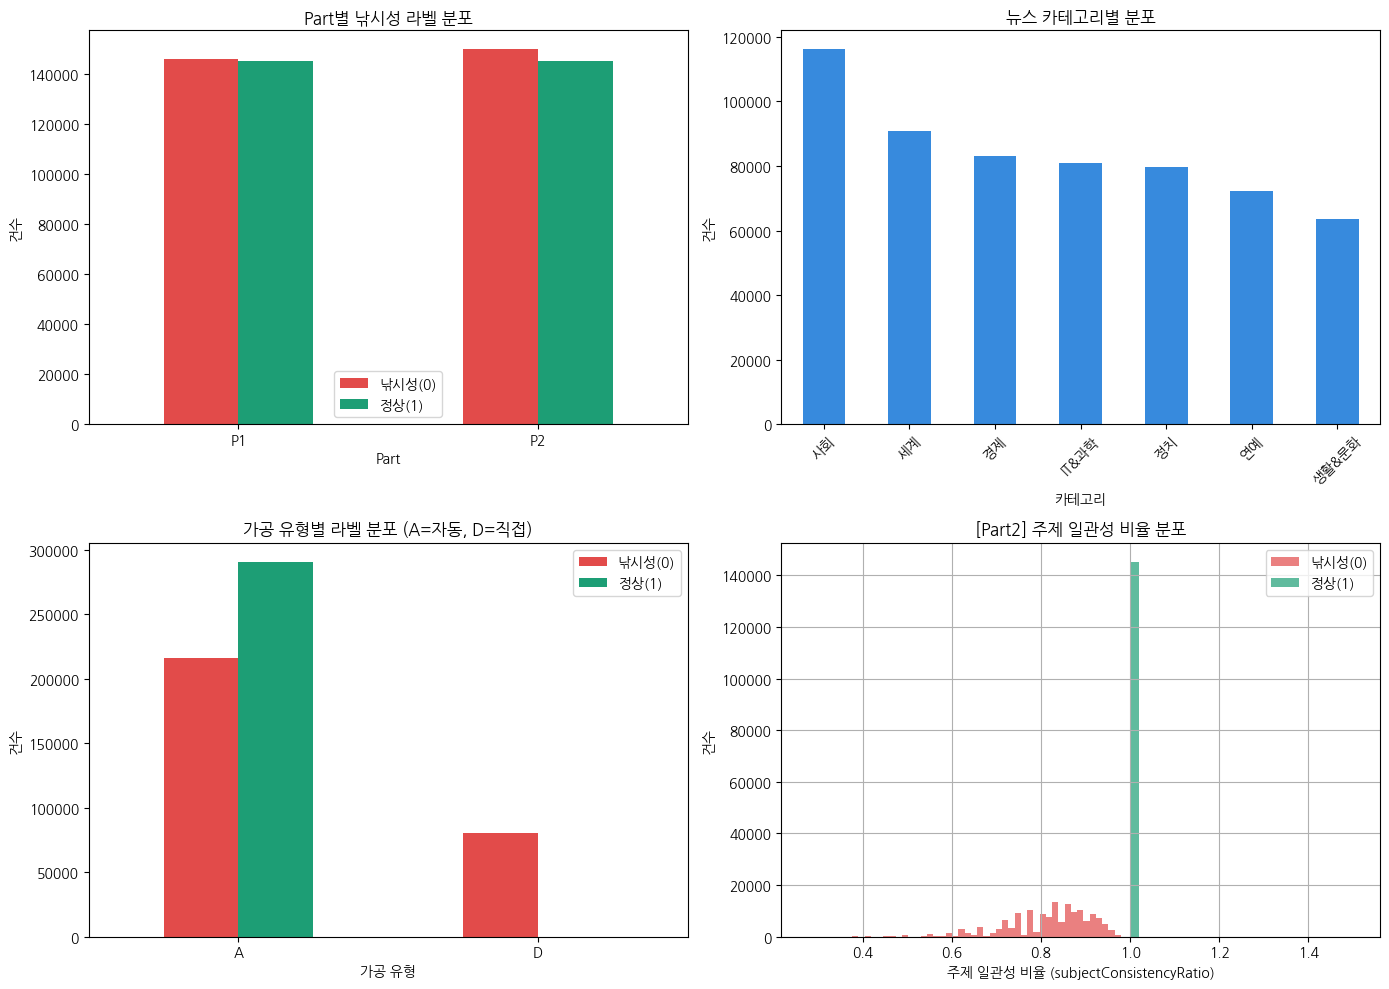

In [14]:
import matplotlib.pyplot as plt
import matplotlib
import subprocess
subprocess.run(['apt-get', '-y', '-qq', 'install', 'fonts-nanum'], capture_output=True)

import matplotlib.font_manager as fm
font_path = '/usr/share/fonts/truetype/nanum/NanumGothic.ttf'
fm.fontManager.addfont(font_path)
plt.rcParams['font.family'] = 'NanumGothic'
plt.rcParams['axes.unicode_minus'] = False



fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# (1) Part별 라벨 분포
ct = pd.crosstab(df['partNum'], df['clickbaitClass'])
ct.plot(kind='bar', ax=axes[0,0], color=['#E24B4A', '#1D9E75'])
axes[0,0].set_title('Part별 낚시성 라벨 분포')
axes[0,0].set_xlabel('Part')
axes[0,0].set_ylabel('건수')
axes[0,0].legend(['낚시성(0)', '정상(1)'])
axes[0,0].tick_params(axis='x', rotation=0)

# (2) 카테고리별 분포
df['newsCategory'].value_counts().plot(kind='bar', ax=axes[0,1], color='#378ADD')
axes[0,1].set_title('뉴스 카테고리별 분포')
axes[0,1].set_xlabel('카테고리')
axes[0,1].set_ylabel('건수')
axes[0,1].tick_params(axis='x', rotation=45)

# (3) 가공 유형별 × 라벨 분포
ct2 = pd.crosstab(df['processType'], df['clickbaitClass'])
ct2.plot(kind='bar', ax=axes[1,0], color=['#E24B4A', '#1D9E75'])
axes[1,0].set_title('가공 유형별 라벨 분포 (A=자동, D=직접)')
axes[1,0].set_xlabel('가공 유형')
axes[1,0].set_ylabel('건수')
axes[1,0].legend(['낚시성(0)', '정상(1)'])
axes[1,0].tick_params(axis='x', rotation=0)

# (4) Part2 주제 일관성 비율 분포
part2 = df[df['partNum'] == 'P2']
part2[part2['clickbaitClass']==0]['subjectConsistencyRatio'].dropna().hist(
    bins=50, alpha=0.7, ax=axes[1,1], color='#E24B4A', label='낚시성(0)')
part2[part2['clickbaitClass']==1]['subjectConsistencyRatio'].dropna().hist(
    bins=50, alpha=0.7, ax=axes[1,1], color='#1D9E75', label='정상(1)')
axes[1,1].set_title('[Part2] 주제 일관성 비율 분포')
axes[1,1].set_xlabel('주제 일관성 비율 (subjectConsistencyRatio)')
axes[1,1].set_ylabel('건수')
axes[1,1].legend()

plt.tight_layout()
plt.savefig('/content/drive/MyDrive/2026 4-1 캡스톤/DATA/Training/TR_EDA_결과.png', dpi=150, bbox_inches='tight')
plt.show()

# **7. CSV 파일로 저장**

In [15]:
# CSV로 저장 (나중에 모델 학습에 사용)
csv_path = '/content/drive/MyDrive/TR_preprocessed.csv'

df.to_csv(csv_path, index=False, encoding='utf-8-sig')

print(f"💾 CSV 저장 완료: {csv_path}")
print(f"  - 전체: {len(df):,}건")
print(f"  - 파일 크기: {os.path.getsize(csv_path) / (1024*1024):.1f} MB")

💾 CSV 저장 완료: /content/drive/MyDrive/TR_preprocessed.csv
  - 전체: 586,741건
  - 파일 크기: 1537.5 MB


# **8. 샘플 데이터 확인**

In [16]:
# Part1 낚시성 기사 샘플
print("=" * 60)
print("📰 [Part1] 낚시성 기사 샘플")
print("=" * 60)
sample_p1 = df[(df['partNum']=='P1') & (df['clickbaitClass']==0)].iloc[0]
print(f"원래 제목: {sample_p1['newsTitle']}")
print(f"낚시 제목: {sample_p1['fakeTitle']}")
print(f"카테고리:  {sample_p1['newsCategory']}")
print(f"참조문장비율: {sample_p1.get('referSentenceRatio', 'N/A')}")
print(f"본문 앞부분: {sample_p1['newsContent'][:200]}...")

# Part2 낚시성 기사 샘플
print("=" * 60)
print("📰 [Part2] 도메인 일관성 부족 기사 샘플")
print("=" * 60)
sample_p2 = df[(df['partNum']=='P2') & (df['clickbaitClass']==0)].iloc[0]
print(f"제목: {sample_p2['newsTitle']}")
print(f"카테고리: {sample_p2['newsCategory']}")
print(f"주제일관성비율: {sample_p2.get('subjectConsistencyRatio', 'N/A')}")
print(f"본문 앞부분: {sample_p2['newsContent'][:200]}...")

📰 [Part1] 낚시성 기사 샘플
원래 제목: 디자이너 1인 多역 시대…제품부터 서비스 디자인까지
낚시 제목: 한 가지만 잘하면 손해 보는 시대, 대표적인 직업에는 어떤 것이 있나?
카테고리:  IT&과학
참조문장비율: 0.05263157894736842
본문 앞부분: 디자인의 중요성은 해가 갈수록 커지고 있다.
제품 간 기술 차이가 크지 않은 가운데, 디자인이 기업의 브랜드 가치를 높이고 사업의 혁신을 가능케 하는 요소로 평가되고 있기 때문이다.
디자이너의 역할도 변하고 있다.
산업혁명 이후 공장 설비에 맞는 효율적 제품을 만들기 위한 설계를 하던 위치에서 제품의 미와 기능의 우선순위를 고민하던 시대를 지나, 사용자의 ...
📰 [Part2] 도메인 일관성 부족 기사 샘플
제목: 윤상 아내 심혜진, \"남편 달라진 모습에 감동\"…백선생님께 감사 전해
카테고리: 연예
주제일관성비율: 0.8333333333333334
본문 앞부분: 윤상 아내 심혜진 윤상 아내 심혜진, 백선생에 감사 \"남편 윤상 몰라보게 달라져\" 윤상 아내인 배우 심혜진이 백종원에게 감사 인사를 전했다.
15일 방송된 tvN '집밥 백선생'에서는 미국에 있는 아내 심혜진과 두 아들에게 손수 집밥을 차려주고 돌아온 윤상의 모습이 전파를 탔다.
이날 방송에선 이렇게 자신의 요리로 오랜만에 만난 가족과 풍성한 만찬을 즐...
